In [1]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import sklearn.model_selection as skm
from ISLP import load_data, confusion_table
from ISLP.models import ModelSpec as MS

from sklearn.tree import (DecisionTreeClassifier as DTC,
                          DecisionTreeRegressor as DTR,
                          plot_tree,
                          export_text)
from sklearn.metrics import (accuracy_score,
                             log_loss)
from sklearn.ensemble import \
     (RandomForestRegressor as RF,
      GradientBoostingRegressor as GBR)
from ISLP.bart import BART

# Importing dataset:

dataset = pd.read_stata(
    r"C:\Users\jonat\OneDrive\Desktop\Uni\Gerber et al 2008\GerberGreenLarimer_APSR_2008_social_pressure.dta",
    convert_categoricals=False
)

# Define treatment dummy variables and add them back into dataset:

dataset["treatment"] = dataset["treatment"].astype(int)
treatment_dummies = pd.get_dummies(dataset['treatment'], prefix='treatment', dtype=int)
dataset = pd.concat([dataset, treatment_dummies], axis=1)

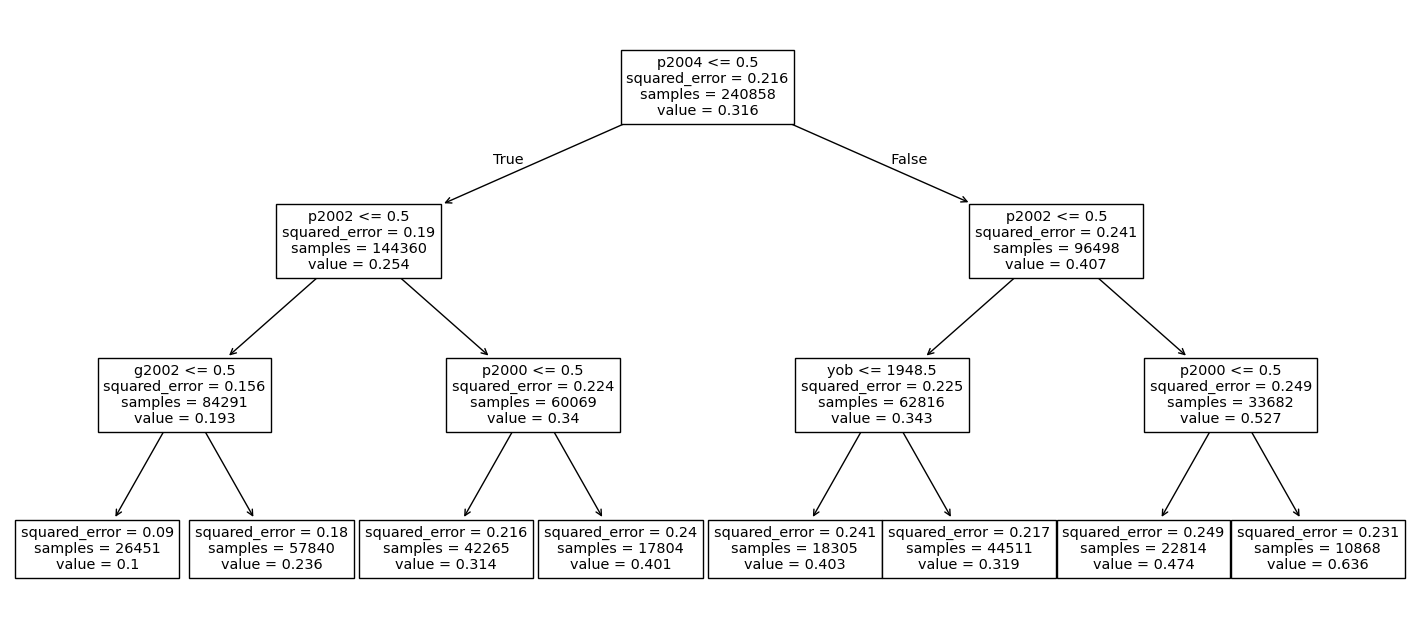

In [2]:
# Fitting Regression Trees

model = MS(dataset.columns.drop(['voted', 'hh_id', 'cluster']), intercept=False)
D = model.fit_transform(dataset)
feature_names = list(D.columns)
X = np.asarray(D)

(X_train,
 X_test,
 y_train,
 y_test) = skm.train_test_split(X,
                                dataset['voted'],
                                test_size=0.3,
                                random_state=0)

reg = DTR(max_depth=3)
reg.fit(X_train, y_train)
ax = subplots(figsize=(18,8))[1]
plot_tree(reg,
          feature_names=feature_names,
          ax=ax);

In [3]:
# Random Forest Model

RF_voted = RF(max_features=6,
               random_state=0).fit(X_train, y_train)
y_hat_RF = RF_voted.predict(X_test)
np.mean((y_test - y_hat_RF)**2)

np.float64(0.23675169137403107)

In [4]:
feature_imp = pd.DataFrame(
    {'importance':RF_voted.feature_importances_},
    index=feature_names)
feature_imp.sort_values(by='importance', ascending=False)

,importance
yob,0.358963
p2004_mean,0.248722
g2004_mean,0.144837
hh_size,0.064657
sex,0.036577
p2004,0.030817
p2002,0.026544
g2000,0.015994
g2002,0.015830
p2000,0.014100


In [5]:
# Boosting Error

boost_data = GBR(n_estimators=100,
                   learning_rate=0.1,
                   max_depth=3,
                   random_state=0)
boost_data.fit(X_train, y_train)

y_hat_boost = boost_data.predict(X_test);

print("Boosting Error:")
print(np.mean((y_test - y_hat_boost)**2))

Boosting Error:
0.19686000810268242


In [6]:
# Tree Error

ccp_path = reg.cost_complexity_pruning_path(X_train, y_train)
kfold = skm.KFold(5,
                  shuffle=True,
                  random_state=10)
grid = skm.GridSearchCV(reg,
                        {'ccp_alpha': ccp_path.ccp_alphas},
                        refit=True,
                        cv=kfold,
                        scoring='neg_mean_squared_error')
G = grid.fit(X_train, y_train)

best_ = grid.best_estimator_

print("Tree Error:")
print(np.mean((y_test - best_.predict(X_test))**2))

Tree Error:
0.2009818486054303


In [7]:
# Bagging Error

bag_data = RF(max_features=X_train.shape[1], random_state=0)
bag_data.fit(X_train, y_train)

y_hat_bag = bag_data.predict(X_test)

print("Bagging Error:")
print(np.mean((y_test - y_hat_bag)**2))

Bagging Error:
0.23605209392209503


In [8]:
# Random Forest Error

RF_data = RF(max_features=6,
               random_state=0).fit(X_train, y_train)
y_hat_RF = RF_data.predict(X_test)

print("Random Forest Error:")
print(np.mean((y_test - y_hat_RF)**2))

Random Forest Error:
0.23675169137403107
